This notebook binds results of different testing methods together into single tables.

In [1]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
import sys
sys.path.append('../utils')
from utils import get_nnmd

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

# Counts

In [2]:
# Get counts
counts = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [3]:
counts.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842


# Guide-qc flags

In [143]:
# annotate flagged guides
all_guide_rankings = pd.read_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v2.tsv', 
                                 sep='\t', index_col=0,
                                 header=[0,1]
                                 ).loc[:, 'summary'][['is_working', 'keep_flag']]

In [144]:
all_guide_rankings

,is_working,keep_flag
sgrna,,
RPL10_ENST00000436473_467,True,True
RAN_ENST00000535090_324,True,True
ACTG1_ENST00000573283_1731,True,True
RPL14_ENST00000416518_279,True,True
CCT8_ENST00000286788_1903,True,True
...,...,...
UBE2I_ENST00000397514_282,True,True
SRRM1_ENST00000323848_574,False,False
UBE2D3_ENST00000394803_368,False,False


# BAGEL

In [197]:
time = 'TP5TP6'

bagel_dfs = []
for filtered in [True, False]:
    name = '_filtered' if filtered else ''
    # get data
    df = pd.read_table(f'../results/bagel2/pooled_screen_1_counts{name}_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])

    bagel_df = df.loc[:, ('alllines', time)].drop(['Recall', 'Precision'], axis=1).rename({'BF': 'Bayesfactor'}, axis=1)
    bagel_df.columns = ['Bagel2'+ name + '_' + x for x in bagel_df.columns]
    bagel_dfs += [bagel_df]
bagel_df = pd.concat(bagel_dfs, axis=1)

In [63]:
bagel_dfs_perline = {}
for line in cell_line_dict.values():
    tdfs = []
    for filtered in [True, False]:
        name = '_filtered' if filtered else ''
        # get data
        df = pd.read_table(f'../results/bagel2/pooled_screen_1_counts{name}_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])

        bagel_df = df.loc[:, (line, time)].drop(['Recall', 'Precision'], axis=1).rename({'BF': 'Bayesfactor'}, axis=1)
        bagel_df.columns = ['Bagel2'+ name + '_' + x for x in bagel_df.columns]
        tdfs += [bagel_df]
    bagel_dfs_perline[line] = pd.concat(tdfs, axis=1)
bagel_df_perline = pd.concat(bagel_dfs_perline, axis=1)

In [64]:
bagel_df_perline

H1975                                         \
           Bagel2_filtered_Bayesfactor Bagel2_filtered_FDR Bagel2_Bayesfactor   
Gene                                                                            
RAN                           1224.141               0.000           1395.486   
MYC                            489.362               0.000            550.753   
FBL                           1198.266               0.000           1219.529   
HNRNPA1                        359.794               0.000            488.730   
EIF4A1                         501.702               0.000            555.385   
...                                ...                 ...                ...   
HOTAIRM1                      -112.609               0.135           -239.430   
PCAT1                          -98.050               0.135           -182.123   
BIN1                          -135.680               0.135           -282.599   
PCBP4                         -135.747               0.135           -199.425   
NT_Control                    -639.545               0.135           -507.967   

                                            H1299                      \
           Bagel2_FDR Bagel2_filtered_Bayesfactor Bagel2_filtered_FDR   
Gene                                                                    
RAN             0.000                    3627.471               0.000   
MYC             0.000                    1436.386               0.000   
FBL             0.000                    1428.767               0.000   
HNRNPA1         0.000                    1213.138               0.000   
EIF4A1          0.000                    1272.320               0.000   
...               ...                         ...                 ...   
HOTAIRM1        0.135                    -146.244               0.135   
PCAT1           0.135                    -175.964               0.135   
BIN1            0.135                     -47.060               0.073   
PCBP4           0.135                    -194.877               0.135   
NT_Control      0.135                    -954.499               0.135   

                                                                A549  \
           Bagel2_Bayesfactor Bagel2_FDR Bagel2_filtered_Bayesfactor   
Gene                                                                   
RAN                  3312.624      0.000                    1901.700   
MYC                  1297.341      0.000                     845.626   
FBL                  1517.062      0.000                     672.038   
HNRNPA1              1170.762      0.000                     930.995   
EIF4A1               1200.300      0.000                    1039.765   
...                       ...        ...                         ...   
HOTAIRM1             -335.167      0.135                    -180.701   
PCAT1                -218.136      0.135                    -148.723   
BIN1                 -161.447      0.135                    -119.108   
PCBP4                -254.294      0.135                    -200.427   
NT_Control           -719.409      0.135                    -538.725   

                                                              
           Bagel2_filtered_FDR Bagel2_Bayesfactor Bagel2_FDR  
Gene                                                          
RAN                      0.000           1178.459      0.000  
MYC                      0.000            505.254      0.000  
FBL                      0.000            452.031      0.000  
HNRNPA1                  0.000            584.437      0.000  
EIF4A1                   0.000            712.434      0.000  
...                        ...                ...        ...  
HOTAIRM1                 0.135           -269.422      0.135  
PCAT1                    0.135           -168.877      0.135  
BIN1                     0.135           -190.658      0.135  
PCBP4                    0.135           -165.336      0.135  
NT_Control               0.135           -328.1

In [236]:
# specificity per line (disfunct)
# sdf = df.loc[:, (cell_line_dict.values(), time)]
# sdf.columns = sdf.columns.droplevel(1)
# spec = sdf.loc[:, (slice(None), 'FDR')].var(axis=1).sort_values(ascending=False)
# spec.head(20)

# sdf = df.loc[:, (cell_line_dict.values(), time)]
# sdf.columns = sdf.columns.droplevel(1)
# spec = (sdf.loc[:, (slice(None), 'BF')].var(axis=1)/ sdf.loc[:, (slice(None), 'BF')].abs().mean(axis=1)).sort_values(ascending=False)
# spec.head(20)

# MAGeCK

## Guide-wise

In [48]:
# Always use unfiltered here, otherwise guides are lost to filtering
filtered = False
name = '_filtered' if filtered else ''

guide_ranking = pd.read_csv(f'../results/mageck/alllines/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0)
# remove columns that are confusing
guide_ranking = guide_ranking.drop(['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment'], axis=1)
guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

# specificity of guides w.r.t. cell lines
guide_rankings = pd.concat({cell_line: pd.read_csv(f'../results/mageck/{cell_line}/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0).drop(
    ['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment', 'Gene'], axis=1)
                  for cell_line in cell_line_dict.values()}, axis=1)
spec = guide_rankings.loc[:, (slice(None), 'FDR')].var(axis=1)
guide_ranking['MAGeCK_cell_line_specificity'] = spec

# Rename
guide_ranking = guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

In [49]:
guide_ranking.head()

,Gene,MAGeCK_score,MAGeCK_pval,MAGeCK_FDR,MAGeCK_cell_line_specificity
sgrna,,,,,
RPL10_ENST00000436473_467,RPL10,27.158,1.996000e-162,1.242500e-158,5.354343e-113
RAN_ENST00000535090_324,RAN,26.162,7.218600e-151,2.246800e-147,2.377042e-107
ACTG1_ENST00000573283_1731,ACTG1,25.906,5.726500e-148,1.188200e-144,8.699468e-109
RPL14_ENST00000416518_279,RPL14,25.654,2.311100e-145,3.596700e-142,1.095423e-105
CCT8_ENST00000286788_1903,CCT8,25.436,1.019500e-142,1.269300e-139,3.374829e-104


In [53]:
# Always use unfiltered here, otherwise guides are lost to filtering
filtered = False
name = '_filtered' if filtered else ''
guide_rankings_perline = {}
for line in cell_line_dict.values():
    guide_ranking = pd.read_csv(f'../results/mageck/{line}/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0)
    # remove columns that are confusing
    guide_ranking = guide_ranking.drop(['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment'], axis=1)
    guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

    # Rename
    guide_ranking = guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)
    guide_rankings_perline[line] = guide_ranking
guide_ranking_perline = pd.concat(guide_rankings_perline, axis=1)

In [54]:
guide_ranking_perline

H1975                              \
                               Gene MAGeCK_score    MAGeCK_pval   
sgrna                                                             
RPL10_ENST00000436473_467     RPL10    27.158000  1.996000e-162   
RAN_ENST00000535090_324         RAN    26.162000  7.218600e-151   
ACTG1_ENST00000573283_1731    ACTG1    25.906000  5.726500e-148   
RPL14_ENST00000416518_279     RPL14    25.654000  2.311100e-145   
CCT8_ENST00000286788_1903      CCT8    25.436000  1.019500e-142   
...                             ...          ...            ...   
UBE2I_ENST00000397514_282     UBE2I     0.007003   9.944100e-01   
SRRM1_ENST00000323848_574     SRRM1     0.005092   9.959400e-01   
UBE2D3_ENST00000394803_368   UBE2D3     0.002355   9.981200e-01   
NFE2L1_ENST00000357480_1853  NFE2L1     0.000622   9.995000e-01   
EWSAT1_ENST00000440444_2433  EWSAT1     0.000469   9.996300e-01   

                                             H1299                             \
                                MAGeCK_FDR    Gene MAGeCK_score   MAGeCK_pval   
sgrna                                                                           
RPL10_ENST00000436473_467    1.242500e-158   RPL10     16.34700  4.071900e-60   
RAN_ENST00000535090_324      2.246800e-147     RAN     15.89900  5.426300e-57   
ACTG1_ENST00000573283_1731   1.188200e-144   ACTG1     15.99700  7.785700e-58   
RPL14_ENST00000416518_279    3.596700e-142   RPL14     15.60900  7.367200e-56   
CCT8_ENST00000286788_1903    1.269300e-139    CCT8     15.62200  5.111600e-55   
...                                    ...     ...          ...           ...   
UBE2I_ENST00000397514_282     9.950500e-01   UBE2I      5.46150  4.721800e-08   
SRRM1_ENST00000323848_574     9.964200e-01   SRRM1      0.34353  7.312000e-01   
UBE2D3_ENST00000394803_368    9.984400e-01  UBE2D3      2.52370  1.161300e-02   
NFE2L1_ENST00000357480_1853   9.996300e-01  NFE2L1      1.49340  1.353300e-01   
EWSAT1_ENST00000440444_2433   9.996300e-01  EWSAT1      0.38163  7.027400e-01   

                                             A549                             \
                               MAGeCK_FDR    Gene MAGeCK_score   MAGeCK_pval   
sgrna                                                                          
RPL10_ENST00000436473_467    1.267400e-56   RPL10     20.64200  1.156800e-94   
RAN_ENST00000535090_324      8.444600e-54     RAN     18.33600  4.245400e-75   
ACTG1_ENST00000573283_1731   1.615500e-54   ACTG1     20.61700  1.944300e-94   
RPL14_ENST00000416518_279    5.732600e-53   RPL14     20.12500  4.342700e-90   
CCT8_ENST00000286788_1903    3.181900e-52    CCT8     19.25200  1.346700e-82   
...                                   ...     ...          ...           ...   
UBE2I_ENST00000397514_282    1.761100e-07   UBE2I      0.23490  8.142900e-01   
SRRM1_ENST00000323848_574    7.939500e-01   SRRM1      2.73430  6.251900e-03   
UBE2D3_ENST00000394803_368   2.307300e-02  UBE2D3      3.15460  1.607200e-03   
NFE2L1_ENST00000357480_1853  2.016900e-01  NFE2L1      1.67630  9.368100e-02   
EWSAT1_ENST00000440444_2433  7.712800e-01  EWSAT1      0.19463  8.456800e-01   

                                           
                               MAGeCK_FDR  
sgrna                                      
RPL10_ENST00000436473_467    6.051600e-91  
RAN_ENST00000535090_324      1.149000e-72  
ACTG1_ENST00000573283_1731   6.051600e-91  
RPL14_ENST00000416518_279    5.406700e-87  
CCT8_ENST00000286788_1903    1.025000e-79  
...                                   ...  
UBE2I_ENST00000397514_282    8.720000e-01  
SRRM1_ENST00000323848_574    1.597000e-02  
UBE2D3_ENST00000394803_368   4.717100e-03  
NFE2L1_ENST00000357480_1853  1.601700e-01  
EWSAT1_ENST00000440444_2433  8.931700e-01  

[6225 rows x 12 columns]

## Gene-wise

In [102]:
mageck_gene_dfs_perline = []
mageck_gene_dfs = []
for filtered in [True, False]:
    name = '_filtered' if filtered else ''
    gene_ranking = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
    gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
    gene_ranking.columns = pd.MultiIndex.from_arrays([
        [x.split('_vs_')[0] for x in gene_ranking.columns],
        [x.split('|')[1] for x in gene_ranking.columns],
        [x.split('|')[2] for x in gene_ranking.columns]
    ])
    
    df = gene_ranking.loc[:, (slice(None), 'neg', slice(None))]  # negative test only
    # Cleanup
    samples = df.columns.get_level_values(0)
    df.columns = df.columns.droplevel(1)
    level_0 = samples.str.split('-').str[2].astype(int).map(cell_line_dict)
    level_2 = samples.str.split('-').str[1]
    df.columns = pd.MultiIndex.from_arrays([level_0, level_2, df.columns.get_level_values(1)])
    df.index = df.index.droplevel(1)
    sdf = df.median(level=(0,2), axis=1)  # median across replicates
    sdf_temp = sdf.copy()
    sdf_temp.columns.set_levels(['MAGeCK'+name+'_' + x for x in sdf_temp.columns.levels[1]], level=1, inplace=True)
    mageck_gene_dfs_perline += [sdf_temp.copy()]
    
    # Reduction
    sdf.loc[:, (slice(None), 'score')] = - sdf.loc[:, (slice(None), 'score')] # flip sign
    mdf = sdf.min(level=1, axis=1)  # smallest value across cell line
    mdf.loc[:, 'score'] = - mdf.loc[:, 'score'] # flip sign back
    mdf = mdf.drop(['goodsgrna', 'rank'], axis=1)
    # sdf.var(axis=1, level=1).drop(['goodsgrna', 'rank'], axis=1).sort_values('p-value', ascending=False).head(20)
    mdf.columns = ['MAGeCK' + name + '_' + x for x in mdf.columns]
    mageck_gene_dfs += [mdf.copy()]
mageck_gene_df = pd.concat(mageck_gene_dfs, axis=1)
mageck_gene_df_perline = pd.concat(mageck_gene_dfs_perline, axis=1)

In [103]:
mageck_gene_df_perline.head()

H1975                                              \
       MAGeCK_filtered_score MAGeCK_filtered_p-value MAGeCK_filtered_fdr   
id                                                                         
RAN             2.306800e-09                0.000005            0.000036   
FBL             2.414600e-05                0.000005            0.000036   
TMSB4X          2.779500e-06                0.000005            0.000036   
SNHG16          4.015600e-07                0.000005            0.000036   
EIF4A1          1.605500e-06                0.000005            0.000036   

                                                                           \
       MAGeCK_filtered_rank MAGeCK_filtered_goodsgrna MAGeCK_filtered_lfc   
id                                                                          
RAN                     1.0                      19.0             -4.9633   
FBL                     7.0                      10.0             -4.5049   
TMSB4X                  5.0                       7.0             -2.8329   
SNHG16                  3.0                      10.0             -3.3369   
EIF4A1                  4.0                       7.0             -4.6764   

                       H1299                                              \
       MAGeCK_filtered_score MAGeCK_filtered_p-value MAGeCK_filtered_fdr   
id                                                                         
RAN             5.619100e-10                0.000005            0.000049   
FBL             3.724300e-05                0.000005            0.000049   
TMSB4X          5.900900e-06                0.000005            0.000049   
SNHG16          1.324400e-06                0.000005            0.000049   
EIF4A1          4.233200e-06                0.000005            0.000049   

                             ...                                          \
       MAGeCK_filtered_rank  ... MAGeCK_fdr MAGeCK_rank MAGeCK_goodsgrna   
id                           ...                                           
RAN                     1.0  ...   0.000095         1.0             19.0   
FBL                     9.0  ...   0.000145        10.0             10.0   
TMSB4X                 10.0  ...   0.000095         5.0              7.0   
SNHG16                  4.0  ...   0.000095         2.0             10.0   
EIF4A1                  5.0  ...   0.000095         5.0              7.0   

                           A549                                        \
       MAGeCK_lfc  MAGeCK_score MAGeCK_p-value MAGeCK_fdr MAGeCK_rank   
id                                                                      
RAN       -3.8762  3.696900e-12       0.000005   0.000107         1.0   
FBL       -3.6723  3.175200e-06       0.000005   0.000107         9.0   
TMSB4X    -2.1184  2.377900e-07       0.000005   0.000107         5.0   
SNHG16    -2.4993  1.061500e-08       0.000005   0.000107         2.0   
EIF4A1    -3.6001  5.564800e-08       0.000005   0.000107         4.0   

                                    
       MAGeCK_goodsgrna MAGeCK_lfc  
id                                  
RAN                20.0    -4.0746  
FBL                10.0    -3.9259  
TMSB4X              7.0    -2.2624  
SNHG16             10.0    -2.9982  
EIF4A1              7.0    -4.4817  

[5 rows x 36 columns]

In [104]:
mageck_gene_df.head()

,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc
id,,,,,,,,
RAN,2.400100e-09,0.000005,0.000036,-4.9633,3.696900e-12,0.000005,0.000091,-4.8215
FBL,3.724300e-05,0.000005,0.000036,-4.5049,3.175200e-06,0.000005,0.000091,-4.1545
TMSB4X,7.073000e-06,0.000005,0.000036,-2.8329,2.377900e-07,0.000005,0.000091,-2.8329
SNHG16,1.324400e-06,0.000005,0.000036,-3.3369,1.127400e-08,0.000005,0.000091,-3.3369
EIF4A1,4.233200e-06,0.000005,0.000036,-4.6764,2.468400e-07,0.000005,0.000091,-4.6764


## Transcript-wise

In [129]:
mageck_transcript_dfs_perline = [] 
mageck_transcript_dfs = []
for filtered in [True, False]:
    name = '_filtered' if filtered else ''
    gene_ranking = pd.read_csv(f'../results/mageck/alllines/transcript_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
    gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
    gene_ranking.columns = pd.MultiIndex.from_arrays([
        [x.split('_vs_')[0] for x in gene_ranking.columns],
        [x.split('|')[1] for x in gene_ranking.columns],
        [x.split('|')[2] for x in gene_ranking.columns]
    ])
    
    df = gene_ranking.loc[:, (slice(None), 'neg', slice(None))]  # negative test only
    # Cleanup
    samples = df.columns.get_level_values(0)
    df.columns = df.columns.droplevel(1)
    level_0 = samples.str.split('-').str[2].astype(int).map(cell_line_dict)
    level_2 = samples.str.split('-').str[1]
    df.columns = pd.MultiIndex.from_arrays([level_0, level_2, df.columns.get_level_values(1)])
    df.index = df.index.droplevel(1)
    sdf = df.median(level=(0,2), axis=1)  # median across replicates
    sdf_temp = sdf.copy()
    sdf_temp.columns.set_levels(['MAGeCK'+name+'_' + x for x in sdf_temp.columns.levels[1]], level=1, inplace=True)
    mageck_transcript_dfs_perline += [sdf_temp.copy()]
    
    # Reduction
    sdf.loc[:, (slice(None), 'score')] = - sdf.loc[:, (slice(None), 'score')] # flip sign
    mdf = sdf.min(level=1, axis=1)  # smallest value across cell line
    mdf.loc[:, 'score'] = - mdf.loc[:, 'score'] # flip sign back
    mdf = mdf.drop(['goodsgrna', 'rank'], axis=1)
    # sdf.var(axis=1, level=1).drop(['goodsgrna', 'rank'], axis=1).sort_values('p-value', ascending=False).head(20)
    mdf.columns = ['MAGeCK' + name + '_' + x for x in mdf.columns]
    mageck_transcript_dfs += [mdf.copy()]
mageck_transcript_df = pd.concat(mageck_transcript_dfs, axis=1)
mageck_transcript_df_perline = pd.concat(mageck_transcript_dfs_perline, axis=1)


In [130]:
mageck_transcript_df_perline.head()

H1975                          \
                MAGeCK_filtered_score MAGeCK_filtered_p-value   
id                                                              
ENST00000451311          2.779500e-06                0.000005   
ENST00000493536          4.015600e-07                0.000005   
ENST00000293831          1.605500e-06                0.000005   
ENST00000230050          2.366900e-05                0.000005   
ENST00000245458          5.270000e-06                0.000005   

                                                          \
                MAGeCK_filtered_fdr MAGeCK_filtered_rank   
id                                                         
ENST00000451311            0.000044                  3.0   
ENST00000493536            0.000044                  2.0   
ENST00000293831            0.000044                  2.0   
ENST00000230050            0.000044                  9.0   
ENST00000245458            0.000044                  4.0   

                                                               \
                MAGeCK_filtered_goodsgrna MAGeCK_filtered_lfc   
id                                                              
ENST00000451311                       7.0             -2.8329   
ENST00000493536                      10.0             -3.3369   
ENST00000293831                       7.0             -4.6764   
ENST00000230050                       5.0             -4.6675   
ENST00000245458                       7.0             -4.3065   

                                H1299                          \
                MAGeCK_filtered_score MAGeCK_filtered_p-value   
id                                                              
ENST00000451311              0.000006                0.000005   
ENST00000493536              0.000001                0.000005   
ENST00000293831              0.000004                0.000005   
ENST00000230050              0.000015                0.000005   
ENST00000245458              0.000005                0.000005   

                                                          ...             \
                MAGeCK_filtered_fdr MAGeCK_filtered_rank  ... MAGeCK_fdr   
id                                                        ...              
ENST00000451311            0.000057                  6.0  ...   0.000134   
ENST00000493536            0.000057                  2.0  ...   0.000134   
ENST00000293831            0.000057                  3.0  ...   0.000134   
ENST00000230050            0.000057                  8.0  ...   0.000134   
ENST00000245458            0.000057                  4.0  ...   0.000134   

                                                                 A549  \
                MAGeCK_rank MAGeCK_goodsgrna MAGeCK_lfc  MAGeCK_score   
id                                                                      
ENST00000451311         4.0              7.0    -2.1184  2.377900e-07   
ENST00000493536         1.0             10.0    -2.4993  1.061500e-08   
ENST00000293831         4.0              7.0    -3.6001  5.564800e-08   
ENST00000230050        21.0              5.0    -2.6773  1.416800e-05   
ENST00000245458         3.0              7.0    -4.0935  2.755800e-07   

                                                                        \
                MAGeCK_p-value MAGeCK_fdr MAGeCK_rank MAGeCK_goodsgrna   
id                                                                       
ENST00000451311       0.000005   0.000111         3.0              7.0   
ENST00000493536       0.000005   0.000111         1.0             10.0   
ENST00000293831       0.000005   0.000111         2.0              7.0   
ENST00000230050       0.000005   0.000111        13.0              5.0   
ENST00000245458       0.000005   0.000111         4.0              7.0   

                            
                MAGeCK_lfc  
id                          
ENST00000451311    -2.2624  
ENST00000493536    -2.9982  
ENST00000293831    -4.4817  
ENST00000230050    -3.0210 

In [126]:
mageck_transcript_df.head()

,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc
id,,,,,,,,
ENST00000451311,0.000007,0.000005,0.000044,-2.8329,2.377900e-07,0.000005,0.000111,-2.8329
ENST00000493536,0.000001,0.000005,0.000044,-3.3369,1.127400e-08,0.000005,0.000111,-3.3369
ENST00000293831,0.000004,0.000005,0.000044,-4.6764,2.468400e-07,0.000005,0.000111,-4.6764
ENST00000230050,0.000024,0.000005,0.000044,-5.4808,3.483300e-05,0.000005,0.000111,-3.5420
ENST00000245458,0.000006,0.000005,0.000044,-4.3065,2.755800e-07,0.000005,0.000111,-4.3065


# Gscreend (Fernanda)

## gene-wise

In [73]:
# aggregate data
filtered = True  # False not working with this, has different format
key = 'Gscreend_results_cleaned_data_Sym_0' if filtered else 'gscreend_results_Sym101_0'

dat = []
for i in [1,2,3]:
    gsc = pd.read_excel(f'../resources/fernanda_gscreend/{key}{i}.xlsx', index_col=0)
    level_0 = gsc.columns.str.split('_').str[-2].astype(int).map(cell_line_dict)
    level_1 = gsc.columns.str.split('_').str[-1]
    level_2 = gsc.columns.str.split('_').str[0]
    gsc.columns = pd.MultiIndex.from_arrays([level_0, level_1, level_2])
    dat.append(gsc)
gsc_df = pd.concat(dat, axis=1)

# Take best value across time points, used across cell lines to derive cell line specificity
gsc_min_df = gsc_df.min(axis=1, level=(0, 2))
cell_line_specificity = gsc_min_df.loc[:, (slice(None), 'FDR')].var(axis=1) * 3

# Take the smallest value across all cell lines and time (if it was a hit in one, it's still a hit)
gsc_min2_df = gsc_df.min(axis=1, level=(2))
gsc_min2_df['cell_line_specificity'] = cell_line_specificity

# add _gscreend suffix to columns
gsc_min2_df.columns = gsc_min2_df.columns.map(lambda x: f'Gscreend_{x}')
# add "Gscreend" to second columns level
gsc_min_df.columns.set_levels(['Gscreend_' + x for x in gsc_min_df.columns.levels[1]], level=1, inplace=True)

In [91]:
# per line
gsc_min_df.head()

H1975                                     H1299  \
          Gscreend_FDR Gscreend_pvalue Gscreend_LFC Gscreend_FDR   
Gene                                                               
AATBC          1.00000        1.000000     0.224941          1.0   
ACTA2-AS1      1.00000        1.000000     0.226708          1.0   
ACTB           0.00000        0.000000    -3.378164          0.0   
ACTG1          0.00000        0.000000    -3.425303          0.0   
ADAR           0.13125        0.011297    -2.398691          1.0   

                                               A549                  \
          Gscreend_pvalue Gscreend_LFC Gscreend_FDR Gscreend_pvalue   
Gene                                                                  
AATBC            1.000000     0.369830          1.0             1.0   
ACTA2-AS1        1.000000     0.255330          1.0             1.0   
ACTB             0.000000    -5.811671          0.0             0.0   
ACTG1            0.000000    -5.650976          0.0             0.0   
ADAR             0.810131    -1.782608          1.0             1.0   

                        
          Gscreend_LFC  
Gene                    
AATBC         0.260911  
ACTA2-AS1     0.181879  
ACTB         -3.441586  
ACTG1        -3.066509  
ADAR         -0.548853

In [92]:
# summary
gsc_min2_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
AATBC,1.00000,1.000000,0.224941,0.000000
ACTA2-AS1,1.00000,1.000000,0.181879,0.000000
ACTB,0.00000,0.000000,-5.811671,0.000000
ACTG1,0.00000,0.000000,-5.650976,0.000000
ADAR,0.13125,0.011297,-2.398691,0.754727


## Transcript-wise (disfunct)

In [51]:
# aggregate data
filtered = True  # False not working with this, has different format
key = 'Gscreend_results_cleaned_data_transcript_level_Sym_0' if filtered else 'gnscreend_results_Sym101_0{i}_Transcript_level'

dat = []
for i in [1,2,3]:
    gsc = pd.read_excel(f'../resources/fernanda_gscreend/{key}{i}.xlsx', index_col=0)
    level_0 = gsc.columns.str.split('_').str[-2].astype(int).map(cell_line_dict)
    level_1 = gsc.columns.str.split('_').str[-1]
    level_2 = gsc.columns.str.split('_').str[0]
    gsc.columns = pd.MultiIndex.from_arrays([level_0, level_1, level_2])
    dat.append(gsc)
gsc_df_trans = pd.concat(dat, axis=1)

# Take best value across time points, used across cell lines to derive cell line specificity
gsc_min_df_trans = gsc_df_trans.min(axis=1, level=(0, 2))
cell_line_specificity = gsc_min_df_trans.loc[:, (slice(None), 'FDR')].var(axis=1) * 3

# Take the smallest value across all cell lines and time (if it was a hit in one, it's still a hit)
gsc_min2_df_trans = gsc_df_trans.min(axis=1, level=(2))
gsc_min2_df_trans['cell_line_specificity'] = cell_line_specificity
# add _gscreend suffix to columns
gsc_min2_df_trans.columns = gsc_min2_df_trans.columns.map(lambda x: f'Gscreend_{x}')

In [61]:
counts.loc[gsc_df_trans.index]

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
Gene,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_3822,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA3683:3800-3822,AGCCACTCTGACTTTGTGACCAG,3822.0,0.799008,Gene_Body,4598.0,...,1299,1399,1262,1365,1330,1180,1270,1540,1127,1411
AATBC_ENST00000400385_827,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0805:805-827,AAGAGACCTGGAGAAGCAGCTTC,827.0,0.707384,Gene_Body,4598.0,...,1254,1695,1438,1387,1270,1286,1258,1648,1371,1398
ACTA2-AS1_ENST00000437930_943,ENST00000437930,ENSG00000180139,ACTA2-AS1,lncRNA,crRNA0901:921-943,CAAACAGGAATACGATGAAGCCG,943.0,0.861795,Gene_Body,2450.0,...,1043,1195,1039,1101,1108,933,948,1216,819,900
ACTB_ENST00000331789_1318,ENST00000331789,ENSG00000075624,ACTB,protein_coding,crRNA1279,GCAACTAAGTCATAGTCCGCCTA,1318.0,0.998200,CDS,NaN,...,395,329,310,226,1047,483,357,307,259,275
ACTB_ENST00000331789_1320,ENST00000331789,ENSG00000075624,ACTB,protein_coding,crRNA1281,ACGCAACTAAGTCATAGTCCGCC,1320.0,0.996500,CDS,NaN,...,185,143,120,50,854,240,196,114,63,57
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2_ENST00000254821_255,ENST00000254821,ENSG00000132485,ZRANB2,protein_coding,crRNA0213:233-255,GCCCAATTCACATTGCTGCAAGT,255.0,1.230637,CDS,2821.0,...,507,566,546,456,682,477,500,475,345,444
ZRANB2_ENST00000370920_165,ENST00000370920,ENSG00000132485,ZRANB2,protein_coding,crRNA0143:143-165,AACTAGCCAGGAATTCAGCTTGT,165.0,1.001390,UTR5,2816.0,...,1732,2165,1765,1895,1963,1621,1827,2278,1739,1775
ZRANB2_ENST00000370920_2493,ENST00000370920,ENSG00000132485,ZRANB2,protein_coding,crRNA2236:2471-2493,CCCATAACAAAAAGCCCCCAAGC,2493.0,1.358361,UTR3,2816.0,...,1121,1339,1106,1051,1303,1036,991,1220,974,1060


In [54]:
gsc

A549                                \
                                    TP1                           TP2   
                                    FDR    pvalue       LFC       FDR   
Gene                                                                    
AATBC_ENST00000400385_3822     1.000000  1.000000  0.211218  1.000000   
AATBC_ENST00000400385_827      1.000000  1.000000  0.310604  1.000000   
ACTA2-AS1_ENST00000437930_943  1.000000  1.000000  0.181879  1.000000   
ACTB_ENST00000331789_1318      0.040107  0.002761 -0.431251  0.045151   
ACTB_ENST00000331789_1320      0.013542  0.000619 -0.594553  0.003623   
...                                 ...       ...       ...       ...   
ZRANB2_ENST00000254821_255     1.000000  1.000000  0.052782  1.000000   
ZRANB2_ENST00000370920_165     1.000000  1.000000  0.119084  1.000000   
ZRANB2_ENST00000370920_2493    1.000000  1.000000  0.276867  1.000000   
ZRANB2_ENST00000370920_541     1.000000  1.000000  0.130714  1.000000   
ZSWIM3_ENST00000255152_32      1.000000  1.000000 -0.114863  1.000000   

                                                                       \
                                                        TP3             
                                 pvalue       LFC       FDR    pvalue   
Gene                                                                    
AATBC_ENST00000400385_3822     1.000000  0.458820  1.000000  1.000000   
AATBC_ENST00000400385_827      1.000000  0.608260  1.000000  1.000000   
ACTA2-AS1_ENST00000437930_943  1.000000  0.334385  1.000000  1.000000   
ACTB_ENST00000331789_1318      0.005141 -1.124234  0.046094  0.005569   
ACTB_ENST00000331789_1320      0.000095 -1.857138  0.004464  0.000143   
...                                 ...       ...       ...       ...   
ZRANB2_ENST00000254821_255     1.000000  0.039987  1.000000  1.000000   
ZRANB2_ENST00000370920_165     1.000000  0.309552  1.000000  1.000000   
ZRANB2_ENST00000370920_2493    1.000000  0.304873  1.000000  1.000000   
ZRANB2_ENST00000370920_541     1.000000  0.000620  1.000000  1.000000   
ZSWIM3_ENST00000255152_32      1.000000  0.062392  1.000000  1.000000   

                                                                       \
                                              TP4                       
                                    LFC       FDR    pvalue       LFC   
Gene                                                                    
AATBC_ENST00000400385_3822     0.486565  1.000000  1.000000  0.570228   
AATBC_ENST00000400385_827      0.597440  1.000000  1.000000  0.832474   
ACTA2-AS1_ENST00000437930_943  0.341468  1.000000  1.000000  0.466112   
ACTB_ENST00000331789_1318     -1.538425  0.612367  0.087681 -1.863502   
ACTB_ENST00000331789_1320     -2.429188  0.001786  0.000048 -2.870997   
...                                 ...       ...       ...       ...   
ZRANB2_ENST00000254821_255    -0.080644  1.000000  1.000000 -0.160646   
ZRANB2_ENST00000370920_165     0.366931  1.000000  1.000000  0.471356   
ZRANB2_ENST00000370920_2493    0.399047  1.000000  1.000000  0.453942   
ZRANB2_ENST00000370920_541    -0.023650  1.000000  1.000000 -0.096491   
ZSWIM3_ENST00000255152_32      0.128821  1.000000  1.000000  0.159714   

                                                                       \
                                    TP5                           TP6   
                                    FDR    pvalue       LFC       FDR   
Gene                                                                    
AATBC_ENST00000400385_3822     1.000000  1.000000  0.539292  1.000000   
AATBC_ENST00000400385_827      1.000000  1.000000  0.859932  1.000000   
ACTA2-AS1_ENST00000437930_943  1.000000  1.000000  0.479884  1.000000   
ACTB_ENST00000331789_1318      0.072439  0.010091 -1.790141  0.677835   
ACTB_ENST00000331789_1320      0.002604  0.000095 -3.246449  0.004310   
...                                 ...       ...       ...       ...   
ZRANB2_ENST000002

In [43]:
gsc_min2_df_trans.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
AATBC_ENST00000400385_3822,1.000000,1.000000,0.060494,0.000000
AATBC_ENST00000400385_827,1.000000,1.000000,0.310604,0.000000
ACTA2-AS1_ENST00000437930_943,1.000000,1.000000,0.181879,0.000000
ACTB_ENST00000331789_1318,0.040107,0.002761,-3.081346,0.907140
ACTB_ENST00000331789_1320,0.000000,0.000000,-6.079155,0.000003


# Merging

## Gene-wise

In [199]:
# alllines
gene_df = pd.merge(gsc_min2_df, mageck_gene_df, left_index=True, right_index=True, how='outer')
gene_df = pd.merge(gene_df, bagel_df, left_index=True, right_index=True, how='outer')
gene_df.to_csv('../results/merged/gene_results.csv')
gene_df.head(10)

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_filtered_Bayesfactor,Bagel2_filtered_FDR,Bagel2_Bayesfactor,Bagel2_FDR
AATBC,1.000000,1.000000,0.224941,0.000000,0.982900,0.744970,0.853306,0.076785,0.996410,0.887360,0.974931,0.069155,-124.940,0.113,-256.648,0.133
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,0.580970,0.264010,0.457302,-0.026468,-41.471,0.000,-84.351,0.012
ACTA2-AS1,1.000000,1.000000,0.181879,0.000000,0.984300,0.728860,0.910502,0.088836,0.975640,0.925350,1.000000,0.067691,-131.842,0.116,-229.044,0.134
ACTB,0.000000,0.000000,-5.811671,0.000000,0.001057,0.000005,0.000036,-3.855500,0.000979,0.000015,0.000226,-2.153600,1111.133,0.000,1219.653,0.000
ACTG1,0.000000,0.000000,-5.650976,0.000000,0.000782,0.000005,0.000036,-2.905100,0.000233,0.000005,0.000091,-2.855300,1438.638,0.000,1527.301,0.000
ADAMTS9-AS2,NaN,NaN,NaN,NaN,0.909790,0.119110,0.282013,-0.165340,0.945310,0.759380,0.937823,0.015704,-47.341,0.006,-168.903,0.090
ADAR,0.131250,0.011297,-2.398691,0.754727,0.020125,0.000005,0.000036,-1.930500,0.018304,0.000291,0.003349,-1.762000,456.051,0.000,506.646,0.000
ADH5,1.000000,1.000000,-0.962940,0.000000,0.333290,0.008219,0.019421,-0.483830,0.311810,0.023413,0.099376,-0.134060,129.337,0.000,137.685,0.000
AFAP1-AS1,1.000000,1.000000,-0.493904,0.000000,0.994860,0.804470,0.961810,0.005320,0.986550,0.685910,0.808134,-0.008897,-50.128,0.012,-53.902,0.007
ALDOA,0.453869,0.055211,-1.442984,0.298259,0.104840,0.000133,0.000365,-1.398000,0.150110,0.021566,0.056737,-0.305360,291.594,0.000,345.275,0.000


In [200]:
# perline
gene_df_perline = pd.merge(gsc_min_df, mageck_gene_df_perline, left_index=True, right_index=True, how='outer')  # only unfiltered for now. too many tables!!!
gene_df_perline = pd.merge(gene_df_perline, bagel_df_perline, left_index=True, right_index=True, how='outer')
gene_df_perline = gene_df_perline.sort_index(axis=1)  # sort columns by line
gene_df_perline.to_csv('../results/merged/gene_results_perline.csv')
gene_df_perline.head(5)

A549                                         \
          Bagel2_Bayesfactor Bagel2_FDR Bagel2_filtered_Bayesfactor   
AATBC                -77.124      0.138                     -60.808   
ACKR2                -15.612      0.009                      -1.521   
ACTA2-AS1            -54.732      0.104                     -45.999   
ACTB                 413.281      0.000                     635.087   
ACTG1                466.985      0.000                     662.590   

                                                                         \
          Bagel2_filtered_FDR Gscreend_FDR Gscreend_LFC Gscreend_pvalue   
AATBC                   0.131          1.0     0.260911             1.0   
ACKR2                   0.000          NaN          NaN             NaN   
ACTA2-AS1               0.089          1.0     0.181879             1.0   
ACTB                    0.000          0.0    -3.441586             0.0   
ACTG1                   0.000          0.0    -3.066509             0.0   

                                                                    ...  \
          MAGeCK_fdr MAGeCK_filtered_fdr MAGeCK_filtered_goodsgrna  ...   
AATBC       0.974931            0.853306                       0.0  ...   
ACKR2       0.668082            0.364833                       1.0  ...   
ACTA2-AS1   1.000000            0.910502                       1.0  ...   
ACTB        0.001492            0.000053                       4.0  ...   
ACTG1       0.000107            0.000053                       5.0  ...   

                              H1975                      \
          MAGeCK_filtered_goodsgrna MAGeCK_filtered_lfc   
AATBC                           0.0             0.29154   
ACKR2                           0.0            -0.20252   
ACTA2-AS1                       1.0             0.12530   
ACTB                            4.0            -3.85550   
ACTG1                           5.0            -2.90510   

                                                                              \
          MAGeCK_filtered_p-value MAGeCK_filtered_rank MAGeCK_filtered_score   
AATBC                    0.787340                626.0              0.971340   
ACKR2                    0.487620                514.0              0.891700   
ACTA2-AS1                0.806440                652.0              0.960640   
ACTB                     0.000005                 47.0              0.000997   
ACTG1                    0.000005                 26.0              0.000243   

                                                                               
          MAGeCK_goodsgrna MAGeCK_lfc MAGeCK_p-value MAGeCK_rank MAGeCK_score  
AATBC                  2.0   0.161490       0.891370       568.0     0.906840  
ACKR2                  3.0  -0.014856       0.264010       374.0     0.456550  
ACTA2-AS1              1.0   0.162060       0.966970       685.0     0.975640  
ACTB                   5.0  -2.153600       0.000015        65.0     0.000838  
ACTG1                  5.0  -2.855300       0.000005        33.0     0.000069  

[5 rows x 57 columns]

## Transcript-wise

In [131]:
# alllines
transcript_df = mageck_transcript_df.copy()#pd.merge(gsc_min2_df_trans, mageck_transcript_df, left_index=True, right_index=True, how='outer')
transcript_df.to_csv('../results/merged/transcript_results.csv')
transcript_df.head()

,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc
id,,,,,,,,
ENST00000451311,0.000007,0.000005,0.000044,-2.8329,2.377900e-07,0.000005,0.000111,-2.8329
ENST00000493536,0.000001,0.000005,0.000044,-3.3369,1.127400e-08,0.000005,0.000111,-3.3369
ENST00000293831,0.000004,0.000005,0.000044,-4.6764,2.468400e-07,0.000005,0.000111,-4.6764
ENST00000230050,0.000024,0.000005,0.000044,-5.4808,3.483300e-05,0.000005,0.000111,-3.5420
ENST00000245458,0.000006,0.000005,0.000044,-4.3065,2.755800e-07,0.000005,0.000111,-4.3065


In [133]:
# per line
transcript_df_perline = mageck_transcript_df_perline.copy()#pd.merge(gsc_min2_df_trans, mageck_transcript_df, left_index=True, right_index=True, how='outer')
transcript_df_perline.to_csv('../results/merged/transcript_results_perline.csv')
transcript_df_perline.head()

H1975                          \
                MAGeCK_filtered_score MAGeCK_filtered_p-value   
id                                                              
ENST00000451311          2.779500e-06                0.000005   
ENST00000493536          4.015600e-07                0.000005   
ENST00000293831          1.605500e-06                0.000005   
ENST00000230050          2.366900e-05                0.000005   
ENST00000245458          5.270000e-06                0.000005   

                                                          \
                MAGeCK_filtered_fdr MAGeCK_filtered_rank   
id                                                         
ENST00000451311            0.000044                  3.0   
ENST00000493536            0.000044                  2.0   
ENST00000293831            0.000044                  2.0   
ENST00000230050            0.000044                  9.0   
ENST00000245458            0.000044                  4.0   

                                                               \
                MAGeCK_filtered_goodsgrna MAGeCK_filtered_lfc   
id                                                              
ENST00000451311                       7.0             -2.8329   
ENST00000493536                      10.0             -3.3369   
ENST00000293831                       7.0             -4.6764   
ENST00000230050                       5.0             -4.6675   
ENST00000245458                       7.0             -4.3065   

                                H1299                          \
                MAGeCK_filtered_score MAGeCK_filtered_p-value   
id                                                              
ENST00000451311              0.000006                0.000005   
ENST00000493536              0.000001                0.000005   
ENST00000293831              0.000004                0.000005   
ENST00000230050              0.000015                0.000005   
ENST00000245458              0.000005                0.000005   

                                                          ...             \
                MAGeCK_filtered_fdr MAGeCK_filtered_rank  ... MAGeCK_fdr   
id                                                        ...              
ENST00000451311            0.000057                  6.0  ...   0.000134   
ENST00000493536            0.000057                  2.0  ...   0.000134   
ENST00000293831            0.000057                  3.0  ...   0.000134   
ENST00000230050            0.000057                  8.0  ...   0.000134   
ENST00000245458            0.000057                  4.0  ...   0.000134   

                                                                 A549  \
                MAGeCK_rank MAGeCK_goodsgrna MAGeCK_lfc  MAGeCK_score   
id                                                                      
ENST00000451311         4.0              7.0    -2.1184  2.377900e-07   
ENST00000493536         1.0             10.0    -2.4993  1.061500e-08   
ENST00000293831         4.0              7.0    -3.6001  5.564800e-08   
ENST00000230050        21.0              5.0    -2.6773  1.416800e-05   
ENST00000245458         3.0              7.0    -4.0935  2.755800e-07   

                                                                        \
                MAGeCK_p-value MAGeCK_fdr MAGeCK_rank MAGeCK_goodsgrna   
id                                                                       
ENST00000451311       0.000005   0.000111         3.0              7.0   
ENST00000493536       0.000005   0.000111         1.0             10.0   
ENST00000293831       0.000005   0.000111         2.0              7.0   
ENST00000230050       0.000005   0.000111        13.0              5.0   
ENST00000245458       0.000005   0.000111         4.0              7.0   

                            
                MAGeCK_lfc  
id                          
ENST00000451311    -2.2624  
ENST00000493536    -2.9982  
ENST00000293831    -4.4817  
ENST00000230050    -3.0210 

## Guide-wise

In [145]:
# alllines
guide_df = guide_ranking.copy()
guide_df = pd.merge(guide_df, all_guide_rankings, left_index=True, right_index=True, how='left')  # add qc flag
guide_df.to_csv('../results/merged/guide_results.csv')

guide_df.head()

,Gene,MAGeCK_score,MAGeCK_pval,MAGeCK_FDR,is_working,keep_flag
sgrna,,,,,,
RPL10_ENST00000436473_467,RPL10,20.642,1.156800e-94,6.051600e-91,True,True
ACTG1_ENST00000573283_1731,ACTG1,20.617,1.944300e-94,6.051600e-91,True,True
RPS17L_ENST00000561157_269,RPS17L,20.561,6.110100e-94,1.267900e-90,True,True
RAD51_ENST00000267868_841,RAD51,20.150,2.704200e-90,4.208500e-87,True,True
RPL14_ENST00000416518_279,RPL14,20.125,4.342700e-90,5.406700e-87,True,True


In [146]:
# perline
guide_df_perline = guide_ranking_perline.copy()
guide_df_perline.to_csv('../results/merged/guide_results_perline.csv')
guide_df_perline.head()

H1975                                             \
                             Gene MAGeCK_score    MAGeCK_pval     MAGeCK_FDR   
sgrna                                                                          
RPL10_ENST00000436473_467   RPL10       27.158  1.996000e-162  1.242500e-158   
RAN_ENST00000535090_324       RAN       26.162  7.218600e-151  2.246800e-147   
ACTG1_ENST00000573283_1731  ACTG1       25.906  5.726500e-148  1.188200e-144   
RPL14_ENST00000416518_279   RPL14       25.654  2.311100e-145  3.596700e-142   
CCT8_ENST00000286788_1903    CCT8       25.436  1.019500e-142  1.269300e-139   

                            H1299                                           \
                             Gene MAGeCK_score   MAGeCK_pval    MAGeCK_FDR   
sgrna                                                                        
RPL10_ENST00000436473_467   RPL10       16.347  4.071900e-60  1.267400e-56   
RAN_ENST00000535090_324       RAN       15.899  5.426300e-57  8.444600e-54   
ACTG1_ENST00000573283_1731  ACTG1       15.997  7.785700e-58  1.615500e-54   
RPL14_ENST00000416518_279   RPL14       15.609  7.367200e-56  5.732600e-53   
CCT8_ENST00000286788_1903    CCT8       15.622  5.111600e-55  3.181900e-52   

                             A549                                           
                             Gene MAGeCK_score   MAGeCK_pval    MAGeCK_FDR  
sgrna                                                                       
RPL10_ENST00000436473_467   RPL10       20.642  1.156800e-94  6.051600e-91  
RAN_ENST00000535090_324       RAN       18.336  4.245400e-75  1.149000e-72  
ACTG1_ENST00000573283_1731  ACTG1       20.617  1.944300e-94  6.051600e-91  
RPL14_ENST00000416518_279   RPL14       20.125  4.342700e-90  5.406700e-87  
CCT8_ENST00000286788_1903    CCT8       19.252  1.346700e-82  1.025000e-79

# Multi-sheet excel file

In [201]:
# Multi-sheet excel
with pd.ExcelWriter('../results/merged/merged_results.xlsx') as writer:
    gene_df.to_excel(writer, sheet_name='gene_results')
    transcript_df.to_excel(writer, sheet_name='transcript_results')
    guide_df.to_excel(writer, sheet_name='guide_results')

In [202]:
# Multi-sheet excel
with pd.ExcelWriter('../results/merged/merged_results_perline.xlsx') as writer:
    gene_df_perline.to_excel(writer, sheet_name='gene_results_perline')
    transcript_df_perline.to_excel(writer, sheet_name='transcript_results_perline')
    guide_df_perline.to_excel(writer, sheet_name='guide_results_perline')

# Comparisons

In [2]:
gene_df = pd.read_csv('../results/merged/gene_results.csv', index_col=0)

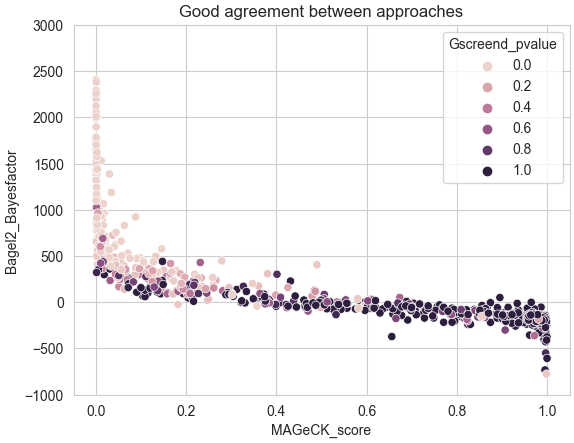

In [4]:
with sns.axes_style('whitegrid'):
    sns.scatterplot(data=gene_df, x='MAGeCK_score', y='Bagel2_Bayesfactor', hue='Gscreend_pvalue')
pl.title('Good agreement between approaches')
pl.ylim(-1000, 3000)
pl.show()

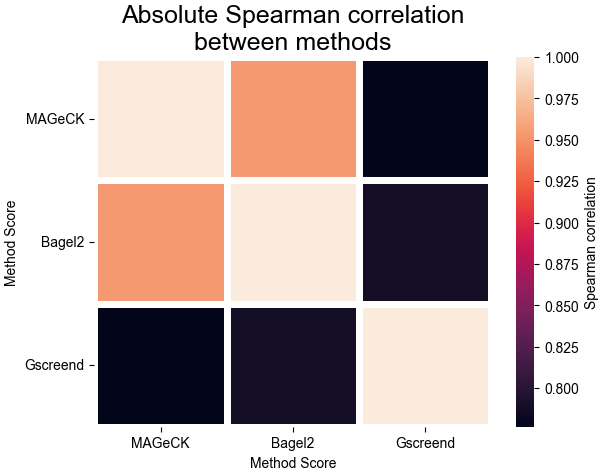

In [13]:
spearman = gene_df[['MAGeCK_score', 'Bagel2_Bayesfactor', 'Gscreend_pvalue']].corr(method='spearman').abs()
sns.heatmap(spearman, annot=False, linewidths=5, linecolor='white', cbar_kws={'label': 'Spearman correlation'})
pl.title('Absolute Spearman correlation\nbetween methods', fontsize=18)
pl.xlabel('Method Score')
pl.ylabel('Method Score')
pl.xticks(ticks=[0.5, 1.5, 2.5], labels=['MAGeCK', 'Bagel2', 'Gscreend'])
pl.yticks(ticks=[0.5, 1.5, 2.5], labels=['MAGeCK', 'Bagel2', 'Gscreend'], rotation=0)
pl.savefig('../results/figures/merged_methods_comparison_spearman.pdf', bbox_inches='tight')
pl.show()

# Evaluation with known essentiality

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.cm import get_cmap

In [15]:
# add essential annotation
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)
gene_df['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in gene_df.index]
gene_df.essentiality.value_counts()

unknown          504
essential        199
non-essential     31
Name: essentiality, dtype: int64

In [16]:
gene_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_filtered_Bayesfactor,Bagel2_filtered_FDR,Bagel2_Bayesfactor,Bagel2_FDR,essentiality
AATBC,1.0,1.0,0.224941,0.0,0.982900,0.744970,0.853306,0.076785,0.996410,0.887360,0.974931,0.069155,-124.940,0.113,-256.648,0.133,unknown
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,0.580970,0.264010,0.457302,-0.026468,-41.471,0.000,-84.351,0.012,unknown
ACTA2-AS1,1.0,1.0,0.181879,0.0,0.984300,0.728860,0.910502,0.088836,0.975640,0.925350,1.000000,0.067691,-131.842,0.116,-229.044,0.134,unknown
ACTB,0.0,0.0,-5.811671,0.0,0.001057,0.000005,0.000036,-3.855500,0.000979,0.000015,0.000226,-2.153600,1111.133,0.000,1219.653,0.000,essential
ACTG1,0.0,0.0,-5.650976,0.0,0.000782,0.000005,0.000036,-2.905100,0.000233,0.000005,0.000091,-2.855300,1438.638,0.000,1527.301,0.000,unknown


In [40]:
def plot_roc(df, key, flip_sign=False, ax=None):
    ax = pl.subplots(figsize=(4,4))[1] if ax is None else ax

    mask = (df.essentiality!='unknown') & ~df[key].isna()
    fpr, tpr, thresholds = roc_curve(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])

    ax.plot(fpr, tpr, linewidth=2, label=key)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{key} ROC Curve\n(n={mask.sum()} genes)')
    

In [41]:
scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']

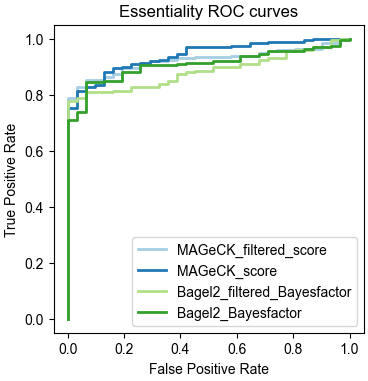

In [53]:
ax = pl.subplots(figsize=(4,4))[1]
import matplotlib.cm as cm
ax.set_prop_cycle('color', cm.get_cmap('Paired')(np.arange(0,4)))
for score, flip in zip(scores, [True, True, False, False]):
    plot_roc(gene_df, score, flip_sign=flip, ax=ax)
ax.legend()
ax.set_title('Essentiality ROC curves')
pl.savefig(f'../results/figures/joint_ROC_curves.pdf', bbox_inches='tight', dpi=300)
pl.show()

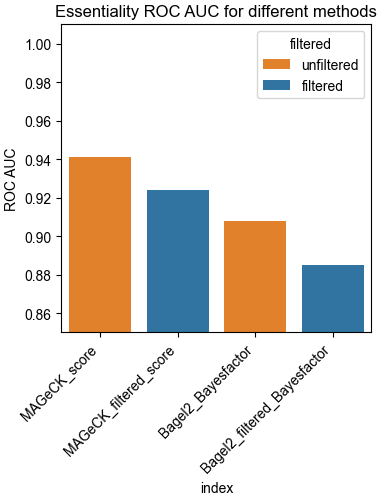

In [58]:
# ROC AUC scores
def get_auc(df, key, flip_sign=False):
    mask = (df.essentiality!='unknown') & ~df[key].isna()
    auc = roc_auc_score(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])
    if auc < 0.5:
        auc = 1-auc # flipped signs
    return auc

scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
score_df = pd.Series({score: get_auc(gene_df, score) for score in scores}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, hue='filtered', dodge=False, palette={'filtered': 'tab:blue', 'unfiltered': 'tab:orange'})
pl.xticks(rotation=45, ha='right')
pl.ylabel('ROC AUC')
pl.title('Essentiality ROC AUC for different methods')
pl.ylim(0.85, 1.01)
pl.savefig(f'../results/figures/ROC_AUC_scores_barplot.pdf', bbox_inches='tight', dpi=300)
pl.show()

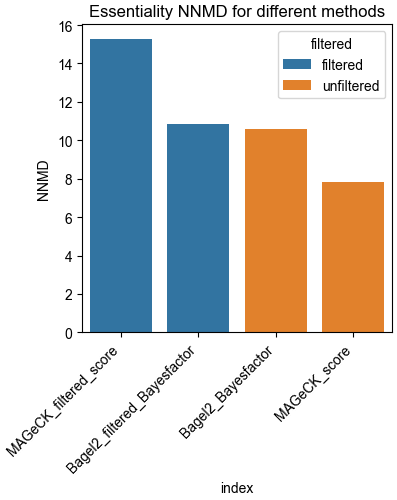

In [59]:
# NNMD
scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
score_df = pd.Series({score: get_nnmd(gene_df, score) for score in scores}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, hue='filtered', dodge=False, palette={'filtered': 'tab:blue', 'unfiltered': 'tab:orange'})
pl.xticks(rotation=45, ha='right')
pl.ylabel('NNMD')
pl.title('Essentiality NNMD for different methods')
pl.savefig(f'../results/figures/NNMD_scores_barplot.pdf', bbox_inches='tight', dpi=300)
pl.show()